# xSIMPSON v3: batting-only, contact-adjusted prototype

The ground-ball singles model and its saved results remain a diagnostic below.
The second section extends accounting to all fair contact, including home runs,
plus observed unintentional walks and HBP per official PA.

**2026 is a development evaluation**, because it helped motivate this project.
Train on 2024-2025, exclude Chandler Simpson (802415) from all fitting and fallback
estimates, and retain the existing degree-2 logistic settings without 2026 tuning.
This is contact-adjusted accounting using observed contact, not a prospective skill
forecast. Baserunning and xSIMPSON+ remain later stages.

## Ground-ball singles diagnostic

In [1]:
import csv
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.calibration import CalibrationDisplay, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

In [2]:
TRAIN_YEARS = [2024, 2025]
TEST_YEAR = 2026
SIMPSON_ID = 802415
DOWNLOAD = False
YEARS = TRAIN_YEARS + [TEST_YEAR]
SPEED_YEARS = sorted({year - 1 for year in YEARS})
BATCH_DAYS = 14
MAX_RETRIES = 3
# Avoid future dates and today's incomplete games.
AS_OF_DATE = (
    pd.Timestamp.now(tz="America/New_York").normalize().tz_localize(None)
    - pd.Timedelta(days=1)
)

In [3]:
# Support a kernel started in either the project root or SIMPSONv3.
NOTEBOOK_DIR = Path.cwd().resolve()
if (NOTEBOOK_DIR / "SIMPSONv3" / "main.ipynb").is_file():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "SIMPSONv3"
if not (NOTEBOOK_DIR / "main.ipynb").is_file():
    raise FileNotFoundError("Start the kernel in SIMPSON or SIMPSONv3.")
DATA_DIR = (NOTEBOOK_DIR.parent / "data").resolve()
LEADERBOARD_DIR = NOTEBOOK_DIR.parent / "leaderboards"
DATA_DIR.mkdir(parents=True, exist_ok=True)
LEADERBOARD_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = LEADERBOARD_DIR / "xsimpson_v3_ground_ball_results.csv"

pitch_keys = ["game_pk", "at_bat_number", "pitch_number"]
required_columns = [
    "game_date", *pitch_keys, "batter", "events", "bb_type",
    "launch_speed", "launch_angle", "stand", "hc_x", "hc_y", "game_type", "des",
]
speed_columns = ["player_id", "season", "sprint_speed"]
print("Data folder:", DATA_DIR)
print("Player-table destination:", RESULTS_PATH)

Data folder: C:\Users\isaac\CodingProjects\SIMPSON\data
Player-table destination: C:\Users\isaac\CodingProjects\SIMPSON\leaderboards\xsimpson_v3_ground_ball_results.csv


In [4]:
def fetch_with_retries(fetch, *args, **kwargs):
    for attempt in range(MAX_RETRIES):
        try:
            return fetch(*args, **kwargs)
        except (requests.exceptions.RequestException, pd.errors.EmptyDataError):
            if attempt == MAX_RETRIES - 1:
                raise
            delay = 2 ** (attempt + 1)
            print(f"Request failed; retrying in {delay} seconds.", flush=True)
            time.sleep(delay)

In [5]:
def download_statcast_year(year):
    output_path = DATA_DIR / f"statcast_{year}.csv"
    if output_path.is_file() and year < AS_OF_DATE.year:
        try:
            sample = pd.read_csv(output_path, nrows=1)
            if not sample.empty and set(required_columns).issubset(sample.columns):
                print(f"Using {output_path.name}", flush=True)
                return
        except (pd.errors.EmptyDataError, pd.errors.ParserError):
            pass

    start_date = pd.Timestamp(year=year, month=3, day=1)
    end_date = min(pd.Timestamp(year=year, month=11, day=30), AS_OF_DATE)
    partial_path = output_path.with_suffix(".partial.csv")
    wrote_batch = False
    for batch_start in pd.date_range(start_date, end_date, freq=f"{BATCH_DAYS}D"):
        batch_end = min(batch_start + pd.Timedelta(days=BATCH_DAYS - 1), end_date)
        print(f"{year}: {batch_start.date()} through {batch_end.date()}", flush=True)
        batch = fetch_with_retries(
            statcast,
            batch_start.strftime("%Y-%m-%d"),
            batch_end.strftime("%Y-%m-%d"),
            parallel=True,
            verbose=False,
        )
        if batch.empty:
            continue
        missing = sorted(set(required_columns) - set(batch.columns))
        if missing:
            raise ValueError(f"Statcast {year} batch missing columns: {missing}")
        # The first nonempty batch writes the header; later batches append.
        batch[required_columns].to_csv(
            partial_path,
            mode="a" if wrote_batch else "w",
            header=not wrote_batch,
            index=False,
        )
        wrote_batch = True
    if not wrote_batch:
        raise ValueError(f"No Statcast data returned for {year}; no file published.")
    partial_path.replace(output_path)
    print(f"Saved {output_path.name}", flush=True)

In [6]:
if DOWNLOAD:
    from pybaseball import cache, statcast, statcast_sprint_speed

    cache.enable()
    for year in YEARS:
        download_statcast_year(year)

In [7]:
if DOWNLOAD:
    speed_path = DATA_DIR / "sprint_speed.csv"
    cached_speed = pd.DataFrame()
    if speed_path.is_file():
        try:
            cached_speed = pd.read_csv(speed_path)
        except (pd.errors.EmptyDataError, pd.errors.ParserError):
            pass
    speed_ready = (
        set(speed_columns).issubset(cached_speed.columns)
        and set(SPEED_YEARS).issubset(cached_speed["season"].dropna().unique())
    )
    if not speed_ready:
        speed_download = pd.concat(
            [
                fetch_with_retries(statcast_sprint_speed, year).assign(season=year)
                for year in SPEED_YEARS
            ],
            ignore_index=True,
        )
        if not set(speed_columns).issubset(speed_download.columns):
            raise ValueError("Sprint Speed response is missing required columns.")
        if set(speed_download["season"].unique()) != set(SPEED_YEARS):
            raise ValueError("Sprint Speed response is missing required seasons.")
        partial_speed_path = speed_path.with_suffix(".partial.csv")
        speed_download.to_csv(partial_speed_path, index=False)
        partial_speed_path.replace(speed_path)
    print("Sprint Speed seasons required:", SPEED_YEARS)

In [8]:
def load_csv(path, columns):
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Run downloads with DOWNLOAD = True.")
    with path.open(encoding="utf-8-sig", newline="") as handle:
        header = next(csv.reader(handle), [])
    missing = sorted(set(columns) - set(header))
    if missing or len(header) != len(set(header)):
        raise ValueError(
            f"{path.name}: missing columns {missing} or duplicate header names. "
            "Download the CSV again."
        )
    try:
        data = pd.read_csv(path, usecols=columns, low_memory=False)
    except (pd.errors.EmptyDataError, pd.errors.ParserError) as error:
        raise ValueError(f"{path.name}: empty or malformed CSV.") from error
    if data.empty:
        raise ValueError(f"{path.name}: CSV has a header but no rows.")
    return data

In [9]:
season_frames = []
data_checks = []
for year in YEARS:
    path = DATA_DIR / f"statcast_{year}.csv"
    frame = load_csv(path, required_columns)
    frame["game_date"] = pd.to_datetime(frame["game_date"], errors="raise")
    if not frame["game_date"].dt.year.eq(year).all():
        raise ValueError(f"{path.name}: missing dates or dates outside {year}.")
    for column in pitch_keys + ["batter", "launch_speed", "launch_angle", "hc_x", "hc_y"]:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    if frame[pitch_keys + ["batter"]].isna().any().any():
        raise ValueError(f"{path.name}: missing pitch or batter keys.")
    duplicate_pitches = int(frame.duplicated(pitch_keys).sum())
    if duplicate_pitches:
        raise ValueError(f"{path.name}: {duplicate_pitches} duplicate pitch records.")
    data_checks.append({
        "season": year, "rows": len(frame), "duplicate_pitches": duplicate_pitches,
        "first_date": frame["game_date"].min(),
        "last_date": frame["game_date"].max(),
    })
    season_frames.append(frame)
plays = pd.concat(season_frames, ignore_index=True)
assert not plays.duplicated(pitch_keys).any(), "Duplicate pitch keys across files"
del season_frames, frame

data_checks = pd.DataFrame(data_checks).set_index("season")
display(data_checks)
print("Verified headers, expected seasons, and unique game/at-bat/pitch keys.")

,rows,duplicate_pitches,first_date,last_date
season,,,,
2024,760249,0,2024-03-15,2024-10-30
2025,770795,0,2025-03-15,2025-11-01
2026,766340,0,2026-03-15,2026-10-28


Verified headers, expected seasons, and unique game/at-bat/pitch keys.


In [10]:
speed = load_csv(DATA_DIR / "sprint_speed.csv", speed_columns)
for column in speed_columns:
    speed[column] = pd.to_numeric(speed[column], errors="raise")
if speed[["player_id", "season"]].isna().any().any():
    raise ValueError("sprint_speed.csv contains missing player or season keys.")
missing_seasons = sorted(set(SPEED_YEARS) - set(speed["season"].unique()))
if missing_seasons:
    raise ValueError(f"sprint_speed.csv is missing preceding seasons: {missing_seasons}")
speed = speed.loc[speed["season"].isin(SPEED_YEARS)].copy()
if speed.duplicated(["player_id", "season"]).any():
    raise ValueError("sprint_speed.csv has duplicate player-season keys.")
display(speed.groupby("season").agg(
    players=("player_id", "size"), available_speeds=("sprint_speed", "count"),
))

,players,available_speeds
season,,
2023,583,583
2024,566,566
2025,579,579


In [11]:
# Truncated appearances are not completed PA and must not inflate PA totals.
plate_appearances = plays.loc[
    plays["game_type"].eq("R") & plays["events"].notna()
    & plays["events"].ne("truncated_pa"),
    required_columns,
].copy()
assert not plate_appearances.duplicated(["game_pk", "at_bat_number"]).any()
plate_appearances["season"] = plate_appearances["game_date"].dt.year
plate_appearances["speed_season"] = plate_appearances["season"] - 1

speed_keys = speed.rename(
    columns={"player_id": "batter", "season": "source_speed_season"}
)
plate_appearances = plate_appearances.merge(
    speed_keys[["batter", "source_speed_season", "sprint_speed"]],
    left_on=["batter", "speed_season"],
    right_on=["batter", "source_speed_season"],
    how="left", validate="many_to_one",
)
matched_speed = plate_appearances["source_speed_season"].notna()
assert plate_appearances.loc[matched_speed, "source_speed_season"].eq(
    plate_appearances.loc[matched_speed, "season"] - 1
).all(), "A speed record came from the wrong season"
display(plate_appearances.groupby("season").agg(
    completed_PA=("batter", "size"),
    matched_prior_speed_records=("source_speed_season", "count"),
    available_speeds=("sprint_speed", "count"),
))
print("Sprint Speed joined by batter ID and preceding season only.")

,completed_PA,matched_prior_speed_records,available_speeds
season,,,
2024,182449,165182,165182
2025,182926,161167,161167
2026,183849,159822,159822


Sprint Speed joined by batter ID and preceding season only.


In [12]:
grounders = plate_appearances.loc[
    plate_appearances["bb_type"].eq("ground_ball")
].copy()
grounders["single"] = grounders["events"].eq("single").astype(int)
grounders["missing_coordinates"] = grounders[["hc_x", "hc_y"]].isna().any(axis=1)
display(grounders.groupby(["season", "single"]).agg(
    grounders=("single", "size"),
    missing_coordinates=("missing_coordinates", "mean"),
    available_speeds=("sprint_speed", "count"),
))

grounders  missing_coordinates  available_speeds
season single                                                  
2024   0           41197             0.000073             37273
       1           11889             0.000252             10769
2025   0           41072             0.000292             35855
       1           11848             0.000084             10393
2026   0           40926             0.000220             35466
       1           11873             0.000084             10240

In [13]:
model_data = grounders.dropna(
    subset=["launch_speed", "launch_angle", "hc_x", "hc_y", "stand"]
).copy()

# Approximate home plate origin in Savant chart coordinates.
model_data["spray_angle"] = np.degrees(
    np.arctan2(model_data["hc_x"] - 125.42, 198.27 - model_data["hc_y"])
)
model_data["left_handed"] = model_data["stand"].eq("L").astype(int)
model_data["speed_missing"] = model_data["sprint_speed"].isna().astype(int)

In [14]:
assert max(TRAIN_YEARS) < TEST_YEAR
train_mask = (
    model_data["season"].isin(TRAIN_YEARS)
    & model_data["batter"].ne(SIMPSON_ID)
)
train_data = model_data.loc[train_mask].copy()
test_data = model_data.loc[model_data["season"].eq(TEST_YEAR)].copy()
assert len(train_data) and len(test_data), "Check years and data coverage"
assert train_data["single"].nunique() == 2
assert not train_data["batter"].eq(SIMPSON_ID).any()

# Estimate the replacement before changing either split; never use 2026 speed.
median_speed = train_data["sprint_speed"].median()
assert pd.notna(median_speed), "No training speed data matched"
for frame in (train_data, test_data):
    frame["sprint_speed"] = frame["sprint_speed"].fillna(median_speed)
print("Training rows:", len(train_data), "Development evaluation rows:", len(test_data))
print("Simpson training rows:", train_data["batter"].eq(SIMPSON_ID).sum())
print("Training-only median Sprint Speed:", median_speed)
print("Missing-speed fraction, train:", train_data["speed_missing"].mean())
print("Missing-speed fraction, 2026:", test_data["speed_missing"].mean())

Training rows: 105003 Development evaluation rows: 52310
Simpson training rows: 0
Training-only median Sprint Speed: 27.5
Missing-speed fraction, train: 0.10850166185728027
Missing-speed fraction, 2026: 0.1344484802141082


In [15]:
baseline_columns = [
    "launch_speed", "launch_angle", "sprint_speed", "left_handed", "speed_missing",
]
full_columns = baseline_columns + ["spray_angle"]
scores = []

# Preserve the existing degree, C, and iteration limit; no 2026 tuning.
# Both models include degree-2 terms. The full model adds direction interactions,
# including spray_angle * sprint_speed and spray_angle * left_handed.
for name, columns in [("baseline", baseline_columns), ("full", full_columns)]:
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=2000),
    )
    model.fit(train_data[columns], train_data["single"])
    assert model.named_steps["standardscaler-1"].n_samples_seen_ == len(train_data)
    test_data[name] = model.predict_proba(test_data[columns])[:, 1]
    assert np.isfinite(test_data[name]).all() and test_data[name].between(0, 1).all()
    scores.append({
        "model": name,
        "Brier": brier_score_loss(test_data["single"], test_data[name]),
        "log_loss": log_loss(test_data["single"], test_data[name], labels=[0, 1]),
    })
print("Both models scored the same", len(test_data), "2026 ground balls.")

Both models scored the same 52310 2026 ground balls.


In [16]:
score_table = pd.DataFrame(scores).set_index("model")
metric_comparison = score_table.T.rename_axis("metric")
metric_comparison["full_minus_baseline"] = (
    metric_comparison["full"] - metric_comparison["baseline"]
)
metric_comparison["improvement_percent"] = (
    -100 * metric_comparison["full_minus_baseline"] / metric_comparison["baseline"]
)
metric_comparison["full_improves"] = metric_comparison["full_minus_baseline"].lt(0)
print("Ground-ball prototype: 2026 development evaluation; lower loss is better.")
display(metric_comparison.round(6))
metric_comparison.to_csv(LEADERBOARD_DIR / "xsimpson_v3_ground_ball_metrics.csv")

Ground-ball prototype: 2026 development evaluation; lower loss is better.


model,baseline,full,full_minus_baseline,improvement_percent,full_improves
metric,,,,,
Brier,0.153997,0.149218,-0.004779,3.103346,True
log_loss,0.476124,0.464258,-0.011865,2.492082,True


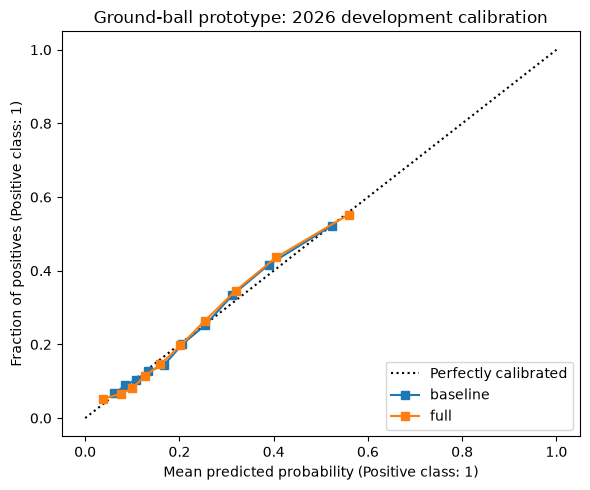

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["baseline", "full"]:
    CalibrationDisplay.from_predictions(
        test_data["single"], test_data[name], n_bins=10,
        strategy="quantile", name=name, ax=ax,
    )
ax.set_title("Ground-ball prototype: 2026 development calibration")
fig.tight_layout()
fig.savefig(LEADERBOARD_DIR / "xsimpson_v3_ground_ball_calibration.png", dpi=160)
plt.show()

The player table sums probabilities over **scored ground balls only**.
`actual_singles` uses those same plays. Coverage is scored / total ground balls;
missing-speed fraction is measured among scored plays. Players with no scoreable
ground balls remain in the table with zero coverage and an undefined missing-speed
fraction. Expected totals are not extrapolated to missing plays.

`placement_adjustment` is full minus baseline expected singles. The models are
fitted separately, so this comparison is not a causal estimate of placement or
proof that a player's placement effect will repeat.

In [18]:
evaluation_grounders = grounders.loc[grounders["season"].eq(TEST_YEAR)]
total_grounders = evaluation_grounders.groupby("batter").size()
results = test_data.groupby("batter").agg(
    scored_grounders=("single", "size"),
    actual_singles=("single", "sum"),
    baseline_expected_singles=("baseline", "sum"),
    full_expected_singles=("full", "sum"),
    missing_speed_fraction=("speed_missing", "mean"),
).reindex(total_grounders.index)
sum_columns = [
    "scored_grounders", "actual_singles",
    "baseline_expected_singles", "full_expected_singles",
]
results[sum_columns] = results[sum_columns].fillna(0)
results[["scored_grounders", "actual_singles"]] = results[
    ["scored_grounders", "actual_singles"]
].astype(int)
results["total_grounders"] = total_grounders
results["coverage"] = results["scored_grounders"] / results["total_grounders"]
results["placement_adjustment"] = (
    results["full_expected_singles"] - results["baseline_expected_singles"]
)
results = results[[
    "total_grounders", "scored_grounders", "coverage", "actual_singles",
    "baseline_expected_singles", "full_expected_singles",
    "placement_adjustment", "missing_speed_fraction",
]].sort_values("full_expected_singles", ascending=False)
assert results["scored_grounders"].sum() == len(test_data)
assert results["scored_grounders"].le(results["total_grounders"]).all()
print("Ground-ball singles prototype player table:")
display(results.head(20).round(3))

Ground-ball singles prototype player table:


,total_grounders,scored_grounders,coverage,actual_singles,baseline_expected_singles,full_expected_singles,placement_adjustment,missing_speed_fraction
batter,,,,,,,,
802415,331,328,0.991,98,67.073,74.583,7.510,0.0
672640,282,279,0.989,82,65.905,69.853,3.948,0.0
665487,258,258,1.000,75,65.609,68.574,2.965,0.0
650490,265,262,0.989,70,57.549,62.796,5.247,0.0
607208,227,226,0.996,60,60.105,62.397,2.292,0.0
663538,251,248,0.988,48,56.834,60.566,3.732,0.0
693304,234,232,0.991,73,57.936,60.236,2.301,0.0
666182,242,241,0.996,52,53.155,58.055,4.901,0.0
665489,227,227,1.000,55,55.936,56.367,0.431,0.0


In [19]:
print("Chandler Simpson: 2026 development evaluation; excluded from fitting.")
display(results.loc[results.index == SIMPSON_ID].round(3))
results.to_csv(RESULTS_PATH)
# Preserve the earlier saved-results path for existing notebook users.
results.to_csv(NOTEBOOK_DIR / "xSIMPSON_ground_ball_results.csv")
print("Saved:", RESULTS_PATH)

Chandler Simpson: 2026 development evaluation; excluded from fitting.


,total_grounders,scored_grounders,coverage,actual_singles,baseline_expected_singles,full_expected_singles,placement_adjustment,missing_speed_fraction
batter,,,,,,,,
802415,331,328,0.991,98,67.073,74.583,7.51,0.0


Saved: C:\Users\isaac\CodingProjects\SIMPSON\leaderboards\xsimpson_v3_ground_ball_results.csv


In [20]:
# Player names are display metadata, cached separately from model inputs.
player_names_path = DATA_DIR / f"player_names_{TEST_YEAR}.csv"
if DOWNLOAD and not player_names_path.is_file():
    response = requests.get(
        "https://statsapi.mlb.com/api/v1/sports/1/players",
        params={"season": TEST_YEAR},
        timeout=30,
    )
    response.raise_for_status()
    player_names = pd.DataFrame(response.json()["people"])
    player_names = player_names[["id", "fullName"]].rename(
        columns={"id": "batter", "fullName": "Name"}
    )
    player_names.to_csv(player_names_path, index=False)
player_names = load_csv(player_names_path, ["batter", "Name"])

In [21]:
# Build and export from saved CSVs; no fitted-model variables are needed.
leaderboard = pd.read_csv(LEADERBOARD_DIR / "xsimpson_v3_ground_ball_results.csv")
player_names = pd.read_csv(
    DATA_DIR / f"player_names_{TEST_YEAR}.csv", usecols=["batter", "Name"],
)
leaderboard = leaderboard.merge(
    player_names, on="batter", how="left", validate="one_to_one",
)
if leaderboard["Name"].isna().any():
    raise ValueError("Player-name lookup is missing leaderboard players.")

season_plays = pd.read_csv(
    DATA_DIR / f"statcast_{TEST_YEAR}.csv",
    usecols=["game_type", "events", "game_pk", "at_bat_number", "batter"],
)
pa_counts = (
    season_plays.loc[season_plays["game_type"].eq("R") & season_plays["events"].notna()
        & season_plays["events"].ne("truncated_pa")]
    .drop_duplicates(["game_pk", "at_bat_number"])
    .groupby("batter").size()
)
leaderboard["PA"] = leaderboard["batter"].map(pa_counts)
leaderboard = leaderboard.sort_values("full_expected_singles", ascending=False)
leaderboard_columns = [
    "Name", "PA", "scored_grounders", "total_grounders", "actual_singles",
    "baseline_expected_singles", "full_expected_singles",
    "placement_adjustment", "coverage", "missing_speed_fraction", "batter",
]
LEADERBOARD_DIR = NOTEBOOK_DIR.parent / "leaderboards"
LEADERBOARD_DIR.mkdir(parents=True, exist_ok=True)
leaderboard[leaderboard_columns].to_csv(
    LEADERBOARD_DIR / "simpsonv3_leaderboard.csv", index=False,
)
display(leaderboard[leaderboard_columns].head(20).round(3))

,Name,PA,scored_grounders,total_grounders,actual_singles,baseline_expected_singles,full_expected_singles,placement_adjustment,coverage,missing_speed_fraction,batter
0,Chandler Simpson,612,328,331,98,67.073,74.583,7.510,0.991,0.0,802415
1,Otto Lopez,687,279,282,82,65.905,69.853,3.948,0.989,0.0,672640
2,Fernando Tatis Jr.,704,258,258,75,65.609,68.574,2.965,1.000,0.0,665487
3,Yandy Díaz,686,262,265,70,57.549,62.796,5.247,0.989,0.0,650490
4,Trea Turner,700,226,227,60,60.105,62.397,2.292,0.996,0.0,607208
5,Nico Hoerner,689,248,251,48,56.834,60.566,3.732,0.988,0.0,663538
6,Nick Gonzales,608,232,234,73,57.936,60.236,2.301,0.991,0.0,693304
7,Bo Bichette,696,241,242,52,53.155,58.055,4.901,0.996,0.0,666182
8,Vladimir Guerrero Jr.,609,227,227,55,55.936,56.367,0.431,1.000,0.0,665489
9,Junior Caminero,702,239,239,50,58.049,55.946,-2.103,1.000,0.0,691406


The ground-ball diagnostic remains unchanged. Its later-season results do not
establish repeatable player skill. The following batting-only extension adds
other fair-contact outcomes and walk/HBP accounting.

## Batting-only, contact-adjusted xSIMPSON

Fair-contact candidates use completed batted-ball event codes, including HR and
sacrifice contact. Catcher interference, walks/HBP, strikeouts, and truncated PA
are not contact. Caught foul-outs identified by `foul` in the play narrative are
excluded from fair contact but retain their PA and zero observed hit credit.
This text-based fair/foul check depends on consistent source descriptions.
[Statcast field definitions](https://baseballsavant.mlb.com/csv-docs) document
`events`, `des`, and the chart coordinates used here.

Classes are `no_hit`, `single`, `double`, `triple`, and `home_run`. Errors and
fielder's choices are `no_hit`: this initial convention gives no separate credit
for reaching on an error or forcing another runner out.

PA, unintentional walks, HBP, intentional walks, and observed hits are counted
from the complete PA data **before any contact-measurement filtering**. PA includes
sacrifices, interference, intentional walks, and HR; truncated PA are excluded.

In [22]:
OUTCOMES = ["no_hit", "single", "double", "triple", "home_run"]
HIT_EVENTS = OUTCOMES[1:]
FAIR_EVENTS = {
    *HIT_EVENTS, "field_out", "force_out", "grounded_into_double_play",
    "sac_fly", "sac_bunt", "field_error", "fielders_choice",
    "fielders_choice_out", "double_play", "sac_fly_double_play", "triple_play",
}
NONCONTACT_EVENTS = {
    "walk", "intent_walk", "hit_by_pitch", "strikeout",
    "strikeout_double_play", "catcher_interf",
}
unknown_events = set(plate_appearances["events"]) - FAIR_EVENTS - NONCONTACT_EVENTS
if unknown_events:
    raise ValueError(f"Review unrecognized PA events before accounting: {unknown_events}")
bat_pa = plate_appearances.copy()
candidates = bat_pa["events"].isin(FAIR_EVENTS)
assert bat_pa.loc[candidates, "des"].notna().all(), "Missing contact descriptions"
bat_pa["foul_out"] = (
    candidates & ~bat_pa["events"].isin(HIT_EVENTS)
    & bat_pa["des"].str.contains(r"\bfoul\b", case=False, na=False)
)
bat_pa["fair_contact"] = candidates & ~bat_pa["foul_out"]
bat_pa["unintentional_walk"] = bat_pa["events"].eq("walk").astype(int)
bat_pa["HBP"] = bat_pa["events"].eq("hit_by_pitch").astype(int)
bat_pa["intentional_walk"] = bat_pa["events"].eq("intent_walk").astype(int)
for outcome in HIT_EVENTS:
    bat_pa[f"observed_{outcome}"] = bat_pa["events"].eq(outcome).astype(int)
display(bat_pa.groupby("season").agg(
    PA=("events", "size"), fair_batted_balls=("fair_contact", "sum"),
    excluded_foul_outs=("foul_out", "sum"),
))

,PA,fair_batted_balls,excluded_foul_outs
season,,,
2024,182449,120662,3541
2025,182926,121407,3481
2026,183849,120973,3638


In [23]:
bat_eval_pa = bat_pa.loc[bat_pa["season"].eq(TEST_YEAR)]
bat_players = bat_eval_pa.groupby("batter").agg(
    PA=("events", "size"), unintentional_walks=("unintentional_walk", "sum"),
    HBP=("HBP", "sum"), intentional_walks=("intentional_walk", "sum"),
    fair_batted_balls=("fair_contact", "sum"), foul_outs=("foul_out", "sum"),
    observed_singles=("observed_single", "sum"),
    observed_doubles=("observed_double", "sum"),
    observed_triples=("observed_triple", "sum"),
    observed_home_runs=("observed_home_run", "sum"),
)
assert bat_players["PA"].gt(0).all()
assert bat_players["PA"].sum() == len(bat_eval_pa)
print("All evaluation PA counted before contact filtering:", len(bat_eval_pa))

All evaluation PA counted before contact filtering: 183849


### Independent season-total validation

Compare complete Statcast PA and observed hits with cached **2026 MLB season
hitting totals**, retrieved from the independent season-statistics endpoint:
[MLB season totals](https://statsapi.mlb.com/api/v1/stats?stats=season&group=hitting&season=2026&sportIds=1&playerPool=ALL&limit=2000).
This comparison does not use model predictions. Keep discrepancies visible rather
than silently replacing player attribution. The headline retains complete
Statcast PA; an official-denominator sensitivity is reported for flagged players.

In [24]:
season_validation = None
independent_path = DATA_DIR / f"mlb_batting_totals_{TEST_YEAR}.csv"
if independent_path.is_file():
    official_totals = load_csv(independent_path, [
        "season", "batter", "Name", "PA", "single", "double", "triple", "home_run",
        "walks", "intentional_walks", "HBP",
    ])
    assert official_totals["season"].eq(TEST_YEAR).all()
    assert official_totals["batter"].is_unique
    official_totals = official_totals.loc[official_totals["PA"].gt(0)].set_index("batter")
    official_totals["unintentional_walks"] = (
        official_totals["walks"] - official_totals["intentional_walks"]
    )
    total_fields = {
        "PA": "PA", "observed_singles": "single", "observed_doubles": "double",
        "observed_triples": "triple", "observed_home_runs": "home_run",
        "unintentional_walks": "unintentional_walks", "HBP": "HBP",
    }
    official_comparison = official_totals[list(total_fields.values())].rename(
        columns={v: f"official_{k}" for k, v in total_fields.items()}
    )
    season_validation = bat_players[list(total_fields)].join(
        official_comparison, how="outer", validate="one_to_one",
    )
    for local, source in total_fields.items():
        season_validation[f"{local}_difference"] = (
            season_validation[local] - season_validation[f"official_{local}"]
        )
    season_validation.to_csv(LEADERBOARD_DIR / "xsimpson_v3_season_total_validation.csv")
else:
    print("Independent season-total source unavailable:", independent_path)

In [25]:
if season_validation is not None:
    difference_columns = [c for c in season_validation if c.endswith("_difference")]
    differences = season_validation[difference_columns]
    source_missing = season_validation[["PA", "official_PA"]].isna().any(axis=1)
    print("Players lacking a corresponding positive-PA season record:", source_missing.sum())
    display(pd.DataFrame({
        "players_with_difference": differences.ne(0).sum(),
        "net_difference": differences.sum(),
    }))
    print("PA discrepancies, Statcast minus independent source:")
    display(season_validation.loc[
        differences.ne(0).any(axis=1) | source_missing,
        ["PA", "official_PA", *difference_columns],
    ])
    print("Simpson independent-total check:")
    display(season_validation.loc[season_validation.index == SIMPSON_ID])

Players lacking a corresponding positive-PA season record: 0


,players_with_difference,net_difference
PA_difference,8,0
observed_singles_difference,0,0
observed_doubles_difference,0,0
observed_triples_difference,0,0
observed_home_runs_difference,0,0
unintentional_walks_difference,0,0
HBP_difference,0,0


PA discrepancies, Statcast minus independent source:


,PA,official_PA,PA_difference,observed_singles_difference,observed_doubles_difference,observed_triples_difference,observed_home_runs_difference,unintentional_walks_difference,HBP_difference
batter,,,,,,,,,
664040,655,656,-1,0,0,0,0,0,0
665861,56,57,-1,0,0,0,0,0,0
667670,202,203,-1,0,0,0,0,0,0
670541,691,692,-1,0,0,0,0,0,0
671732,540,539,1,0,0,0,0,0,0
681351,275,274,1,0,0,0,0,0,0
691373,51,50,1,0,0,0,0,0,0
701305,83,82,1,0,0,0,0,0,0


Simpson independent-total check:


,PA,observed_singles,observed_doubles,observed_triples,observed_home_runs,unintentional_walks,HBP,official_PA,official_observed_singles,official_observed_doubles,...,official_observed_home_runs,official_unintentional_walks,official_HBP,PA_difference,observed_singles_difference,observed_doubles_difference,observed_triples_difference,observed_home_runs_difference,unintentional_walks_difference,HBP_difference
batter,,,,,,,,,,,,,,,,,,,,,
802415,612,153,16,6,0,25,0,612,153,16,...,0,25,0,0,0,0,0,0,0,0


In [26]:
bat_contact = bat_pa.loc[bat_pa["fair_contact"]].copy()
bat_contact["outcome"] = bat_contact["events"].where(
    bat_contact["events"].isin(HIT_EVENTS), "no_hit"
)
bat_contact["outcome_code"] = pd.Categorical(
    bat_contact["outcome"], categories=OUTCOMES
).codes
bat_contact["bb_group"] = bat_contact["bb_type"].fillna("unknown")
bat_contact["spray_angle"] = np.degrees(np.arctan2(
    bat_contact["hc_x"] - 125.42, 198.27 - bat_contact["hc_y"]
))
bat_contact["left_handed"] = bat_contact["stand"].eq("L").astype(int)
bat_contact["speed_missing"] = bat_contact["sprint_speed"].isna().astype(int)
bat_contact["baseline_available"] = (
    np.isfinite(bat_contact[["launch_speed", "launch_angle"]]).all(axis=1)
    & bat_contact["stand"].isin(["L", "R"])
)
bat_contact["direction_available"] = (
    np.isfinite(bat_contact[["hc_x", "hc_y"]]).all(axis=1)
    & np.isfinite(bat_contact["spray_angle"])
)
bat_training_mask = (
    bat_contact["season"].isin(TRAIN_YEARS)
    & bat_contact["batter"].ne(SIMPSON_ID)
)
bat_training = bat_contact.loc[bat_training_mask].copy()
assert bat_training["batter"].ne(SIMPSON_ID).all()
display(pd.crosstab(bat_contact["season"], bat_contact["outcome"]))

outcome,double,home_run,no_hit,single,triple
season,,,,,
2024,7771,5453,80839,25902,697
2025,7745,5650,81269,26115,628
2026,7493,5575,81124,26110,671


Missing measurements have explicit routes. Both multinomial models fit the
same complete-measurement training rows. Their preprocessing fits training data
only. Fitting retains the training-play median speed and missing-speed indicator.
Headline inference below replaces missing speed with the unique-record reference
speed in both scenarios; the old median policy is retained for sensitivity analysis.

For evaluation and batting accounting, use the full model when EV/LA, handedness,
and direction are available. Use the baseline model when only direction is
missing. For missing EV/LA (or handedness), use the empirical five-outcome
frequencies for that batted-ball type in **all 2024-2025 training fair contact**,
excluding Simpson. Unknown types use overall training frequencies. No evaluation
outcomes enter these fallbacks, and no missing contact is silently assigned zero.

Metrics report both an identical complete-measurement sample and all fair contact
with these fallbacks. The latter compares the full scoring policy with baseline
scoring on the same plays. Calibration plots use the all-contact comparison.

In [27]:
bat_median_speed = bat_training["sprint_speed"].median()
assert pd.notna(bat_median_speed), "No training Sprint Speed matched"
bat_prior = bat_training["outcome"].value_counts(normalize=True).reindex(
    OUTCOMES, fill_value=0.0
)
bat_type_priors = pd.crosstab(
    bat_training["bb_group"], bat_training["outcome"], normalize="index"
).reindex(columns=OUTCOMES, fill_value=0.0)
assert np.isclose(bat_prior.sum(), 1)
assert np.allclose(bat_type_priors.sum(axis=1), 1)
bat_contact["sprint_speed"] = bat_contact["sprint_speed"].fillna(bat_median_speed)
bat_fit = bat_contact.loc[
    bat_training_mask & bat_contact["baseline_available"]
    & bat_contact["direction_available"]
].copy()
bat_eval = bat_contact.loc[bat_contact["season"].eq(TEST_YEAR)].copy()
assert len(bat_fit) and len(bat_eval)
assert bat_fit["batter"].ne(SIMPSON_ID).all()
assert set(bat_fit["outcome_code"]) == set(range(len(OUTCOMES)))
print("Training fair contact for fallback:", len(bat_training))
print("Identical multinomial fitting rows:", len(bat_fit))
print("2026 development fair-contact rows:", len(bat_eval))
print("Training-only speed replacement:", bat_median_speed)
display(bat_type_priors.round(5))

Training fair contact for fallback: 241696
Identical multinomial fitting rows: 240784
2026 development fair-contact rows: 120973
Training-only speed replacement: 27.5


outcome,no_hit,single,double,triple,home_run
bb_group,,,,,
fly_ball,0.74428,0.04486,0.04747,0.00712,0.15627
ground_ball,0.75355,0.22395,0.02123,0.00127,0.00000
line_drive,0.37685,0.42400,0.17111,0.01221,0.01582
popup,0.97958,0.01725,0.00300,0.00017,0.00000
unknown,1.00000,0.00000,0.00000,0.00000,0.00000


In [28]:
bat_models = {}
bat_baseline_columns = baseline_columns.copy()
bat_full_columns = bat_baseline_columns + ["spray_angle"]
for name, columns in [
    ("baseline", bat_baseline_columns), ("full", bat_full_columns),
]:
    # lbfgs fits the joint multinomial likelihood for the five outcome classes.
    bat_model = make_pipeline(
        StandardScaler(), PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(), LogisticRegression(solver="lbfgs", C=1.0, max_iter=2000),
    )
    bat_model.fit(bat_fit[columns], bat_fit["outcome_code"])
    assert np.array_equal(bat_model.classes_, np.arange(len(OUTCOMES)))
    assert bat_model.named_steps["standardscaler-1"].n_samples_seen_ == len(bat_fit)
    bat_models[name] = bat_model
print("Five-class models fitted on 2024-2025; Simpson excluded; no 2026 tuning.")

Five-class models fitted on 2024-2025; Simpson excluded; no 2026 tuning.


In [29]:
bat_fallback = pd.DataFrame(
    np.tile(bat_prior.to_numpy(), (len(bat_eval), 1)),
    index=bat_eval.index, columns=OUTCOMES,
)
for bb_type, probabilities in bat_type_priors.iterrows():
    bat_fallback.loc[bat_eval["bb_group"].eq(bb_type)] = probabilities.to_numpy()
bat_base_rows = bat_eval["baseline_available"]
bat_full_rows = bat_base_rows & bat_eval["direction_available"]
bat_baseline_prob = bat_fallback.copy()
bat_baseline_prob.loc[bat_base_rows] = bat_models["baseline"].predict_proba(
    bat_eval.loc[bat_base_rows, bat_baseline_columns]
)
bat_full_prob = bat_baseline_prob.copy()
bat_full_prob.loc[bat_full_rows] = bat_models["full"].predict_proba(
    bat_eval.loc[bat_full_rows, bat_full_columns]
)
bat_probabilities = {"baseline": bat_baseline_prob, "full": bat_full_prob}
for probabilities in bat_probabilities.values():
    assert probabilities.index.equals(bat_eval.index)
    assert np.isfinite(probabilities).all().all()
    assert probabilities.ge(0).all().all() and probabilities.le(1).all().all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-10)
bat_eval["prediction_source"] = np.select(
    [bat_full_rows, bat_base_rows],
    ["full_model", "baseline_direction_fallback"],
    default="training_contact_fallback",
)
print("Every fair-contact probability vector sums to one.")
display(pd.crosstab(bat_eval["bb_group"], bat_eval["prediction_source"]))

Every fair-contact probability vector sums to one.


prediction_source,baseline_direction_fallback,full_model,training_contact_fallback
bb_group,,,
fly_ball,48,32703,14
ground_ball,7,52310,479
line_drive,6,29358,11
popup,1,6033,3


### Speed association at fixed observed contact

Reference speed is the **unweighted mean of measured prior-season speeds across
unique (batter, play-season) records represented in full-model training**. A batter
represented in both training seasons contributes two records; contact volume does
not add weight. Missing speeds and Simpson are excluded.

Use the already fitted pipelines and change only the speed input. Keep contact,
direction, handedness, and the missing-speed indicator fixed. Full-model plays use
the full pipeline twice; direction fallbacks use the baseline pipeline twice;
empirical contact fallbacks are speed-independent in both scenarios.

For missing prior speed, put reference speed in **both** scenarios, giving zero
individualized speed conversion. This changes inference from the earlier
training-play median convention, without refitting preprocessing or coefficients.
The original median-policy predictions remain available for sensitivity analysis.
This decomposition is a **model-based association**, not a causal speed effect.

In [30]:
reference_records = bat_fit.loc[
    bat_fit["speed_missing"].eq(0), ["batter", "season", "sprint_speed"]
].copy()
assert reference_records["batter"].ne(SIMPSON_ID).all()
assert reference_records.groupby(["batter", "season"])["sprint_speed"].nunique().le(1).all()
reference_records = reference_records.drop_duplicates(["batter", "season"])
reference_speed = reference_records["sprint_speed"].mean()
assert np.isfinite(reference_speed)
reference_records.to_csv(LEADERBOARD_DIR / "xsimpson_v3_reference_speed_records.csv", index=False)
print("Reference Sprint Speed:", reference_speed, "ft/s;")
print("Unique measured training batter-season records:", len(reference_records))
print("Training imputation remains:", bat_median_speed, "ft/s; no model refit.")
bat_previous_median_prob = bat_full_prob.copy()
missing_prior_speed = bat_eval["speed_missing"].eq(1)
bat_eval.loc[missing_prior_speed, "sprint_speed"] = reference_speed
player_speed_inputs = bat_eval[bat_full_columns].copy()
reference_speed_inputs = player_speed_inputs.copy()
reference_speed_inputs["sprint_speed"] = reference_speed
assert player_speed_inputs.drop(columns="sprint_speed").equals(
    reference_speed_inputs.drop(columns="sprint_speed")
)

Reference Sprint Speed: 27.384378211716342 ft/s;
Unique measured training batter-season records: 973
Training imputation remains: 27.5 ft/s; no model refit.


In [31]:
bat_speed_predictions = {}
bat_speed_baselines = {}
for scenario, features in [
    ("player_speed", player_speed_inputs), ("reference_speed", reference_speed_inputs),
]:
    probabilities = bat_fallback.copy()
    probabilities.loc[bat_base_rows] = bat_models["baseline"].predict_proba(
        features.loc[bat_base_rows, bat_baseline_columns]
    )
    bat_speed_baselines[scenario] = probabilities.copy()
    probabilities.loc[bat_full_rows] = bat_models["full"].predict_proba(
        features.loc[bat_full_rows, bat_full_columns]
    )
    assert np.isfinite(probabilities).all().all()
    assert probabilities.ge(0).all().all() and probabilities.le(1).all().all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-10)
    bat_speed_predictions[scenario] = probabilities
bat_baseline_prob = bat_speed_baselines["player_speed"]
bat_full_prob = bat_speed_predictions["player_speed"]
bat_reference_prob = bat_speed_predictions["reference_speed"]
bat_probabilities = {"baseline": bat_baseline_prob, "full": bat_full_prob}
assert np.allclose(
    bat_full_prob.loc[missing_prior_speed], bat_reference_prob.loc[missing_prior_speed]
)
assert np.allclose(
    bat_full_prob.loc[~missing_prior_speed], bat_previous_median_prob.loc[~missing_prior_speed]
)
print("Missing measured prior speed:", missing_prior_speed.sum(), "of", len(bat_eval),
      f"({missing_prior_speed.mean():.2%} of fair contact).")
print("All scenarios sum to one; all non-speed inputs held fixed.")

Missing measured prior speed: 15590 of 120973 (12.89% of fair contact).
All scenarios sum to one; all non-speed inputs held fixed.


In [32]:
bat_metric_rows = []
for scope, sample in [
    ("all_contact_with_fallbacks", bat_eval),
    ("complete_measurements", bat_eval.loc[bat_full_rows]),
]:
    groups = [("overall", sample)] + list(sample.groupby("bb_group"))
    for bb_type, group in groups:
        for name, probabilities in bat_probabilities.items():
            prediction = probabilities.loc[group.index]
            row = {
                "evaluation_set": scope, "bb_type": bb_type, "model": name,
                "rows": len(group), "log_loss": log_loss(
                    group["outcome_code"], prediction, labels=np.arange(len(OUTCOMES)),
                ),
            }
            for outcome in OUTCOMES:
                row[f"Brier_{outcome}"] = np.mean(
                    (group["outcome"].eq(outcome).astype(int) - prediction[outcome]) ** 2
                )
            row["Brier_total"] = sum(row[f"Brier_{outcome}"] for outcome in OUTCOMES)
            bat_metric_rows.append(row)
bat_metrics = pd.DataFrame(bat_metric_rows)
bat_metrics.to_csv(LEADERBOARD_DIR / "xsimpson_v3_batting_metrics.csv", index=False)
display(bat_metrics.round(6))

,evaluation_set,bb_type,model,rows,log_loss,Brier_no_hit,Brier_single,Brier_double,Brier_triple,Brier_home_run,Brier_total
0,all_contact_with_fallbacks,overall,baseline,120973,0.724925,0.178144,0.153562,0.051574,0.005442,0.019809,0.408531
1,all_contact_with_fallbacks,overall,full,120973,0.692383,0.170446,0.151470,0.047800,0.005411,0.015678,0.390805
2,all_contact_with_fallbacks,fly_ball,baseline,32765,0.589316,0.125399,0.045452,0.042645,0.007572,0.063888,0.284956
3,all_contact_with_fallbacks,fly_ball,full,32765,0.530623,0.110799,0.046039,0.041533,0.007514,0.048385,0.254270
4,all_contact_with_fallbacks,ground_ball,baseline,52796,0.652960,0.178807,0.175716,0.019322,0.001192,0.000019,0.375056
5,all_contact_with_fallbacks,ground_ball,full,52796,0.641874,0.175483,0.172222,0.018621,0.001187,0.000029,0.367542
6,all_contact_with_fallbacks,line_drive,baseline,29375,1.129953,0.267570,0.261791,0.129288,0.011789,0.010284,0.680721
7,all_contact_with_fallbacks,line_drive,full,29375,1.080711,0.258095,0.258867,0.116092,0.011736,0.010547,0.655336
8,all_contact_with_fallbacks,popup,baseline,6037,0.119494,0.023488,0.019942,0.003954,0.000166,0.000000,0.047549
9,all_contact_with_fallbacks,popup,full,6037,0.122498,0.023636,0.019619,0.004692,0.000166,0.000000,0.048113


In [33]:
bat_comparison = bat_metrics.pivot(
    index=["evaluation_set", "bb_type", "rows"], columns="model",
    values=["log_loss", "Brier_total"] + [f"Brier_{c}" for c in OUTCOMES],
)
bat_changes = pd.DataFrame(index=bat_comparison.index)
for metric in ["log_loss", "Brier_total"] + [f"Brier_{c}" for c in OUTCOMES]:
    bat_changes[f"{metric}_full_minus_baseline"] = (
        bat_comparison[(metric, "full")] - bat_comparison[(metric, "baseline")]
    )
    bat_changes[f"{metric}_full_improves"] = (
        bat_changes[f"{metric}_full_minus_baseline"] < 0
    )
print("2026 development comparison: negative differences mean lower loss.")
display(bat_changes.round(6))
bat_changes.to_csv(LEADERBOARD_DIR / "xsimpson_v3_batting_metric_comparison.csv")

2026 development comparison: negative differences mean lower loss.


log_loss_full_minus_baseline  \
evaluation_set             bb_type     rows                                   
all_contact_with_fallbacks fly_ball    32765                      -0.058693   
                           ground_ball 52796                      -0.011087   
                           line_drive  29375                      -0.049242   
                           overall     120973                     -0.032542   
                           popup       6037                        0.003004   
complete_measurements      fly_ball    32703                      -0.058804   
                           ground_ball 52310                      -0.011190   
                           line_drive  29358                      -0.049270   
                           overall     120404                     -0.032696   
                           popup       6033                        0.003006   

                                               log_loss_full_improves  \
evaluation_set             bb_type     rows                             
all_contact_with_fallbacks fly_ball    32765                     True   
                           ground_ball 52796                     True   
                           line_drive  29375                     True   
                           overall     120973                    True   
                           popup       6037                     False   
complete_measurements      fly_ball    32703                     True   
                           ground_ball 52310                     True   
                           line_drive  29358                     True   
                           overall     120404                    True   
                           popup       6033                     False   

                                               Brier_total_full_minus_baseline  \
evaluation_set             bb_type     rows                                      
all_contact_with_fallbacks fly_ball    32765                         -0.030685   
                           ground_ball 52796                         -0.007515   
                           line_drive  29375                         -0.025385   
                           overall     120973                        -0.017726   
                           popup       6037                           0.000564   
complete_measurements      fly_ball    32703                         -0.030743   
                           ground_ball 52310                         -0.007584   
                           line_drive  29358                         -0.025400   
                           overall     120404                        -0.017810   
                           popup       6033                           0.000564   

                                               Brier_total_full_improves  \
evaluation_set             bb_type     rows                                
all_contact_with_fallbacks fly_ball    32765                        True   
                           ground_ball 52796                        True   
                           line_drive  29375                        True   
                           overall     120973                       True   
                           popup       6037                        False   
complete_measurements      fly_ball    32703                        True   
                           ground_ball 52310                        True   
                           line_drive  29358                        True   
                           overall     120404                       True   
                           popup       6033                        False   

                                               Brier_no_hit_full_minus_baseline  \
evaluation_set             bb_type     rows                                       
all_contact_with_fallbacks fly_ball    32765                          -0.014600   
                           ground_ball 52796                          -0.0

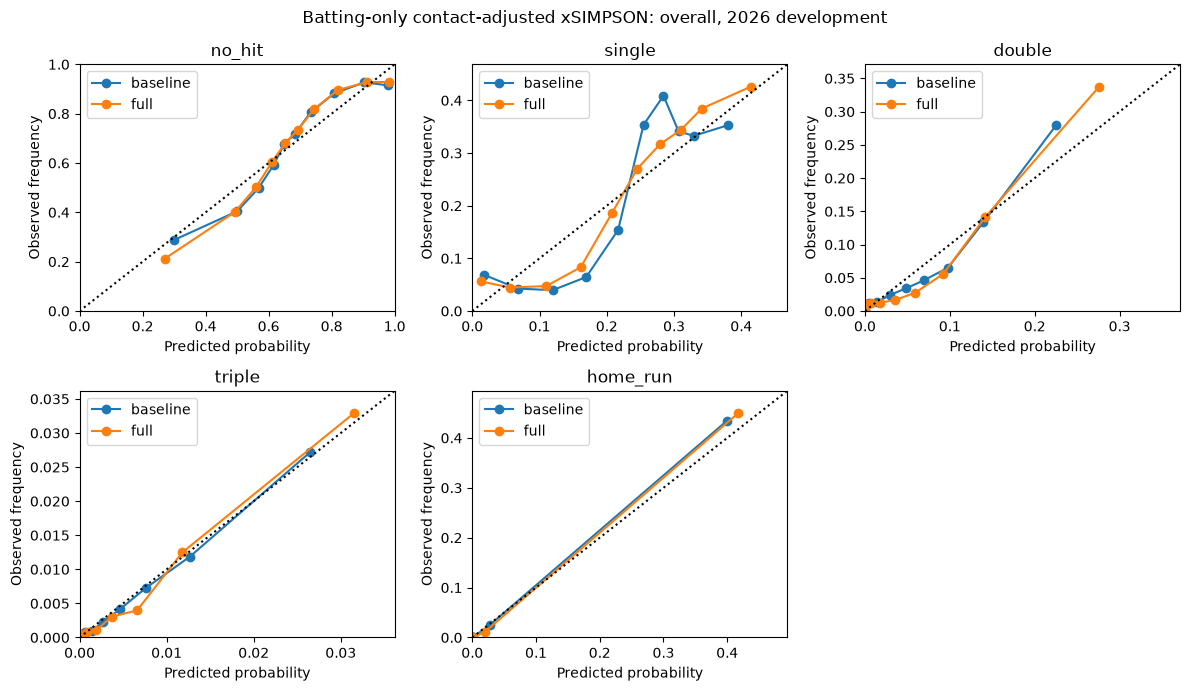

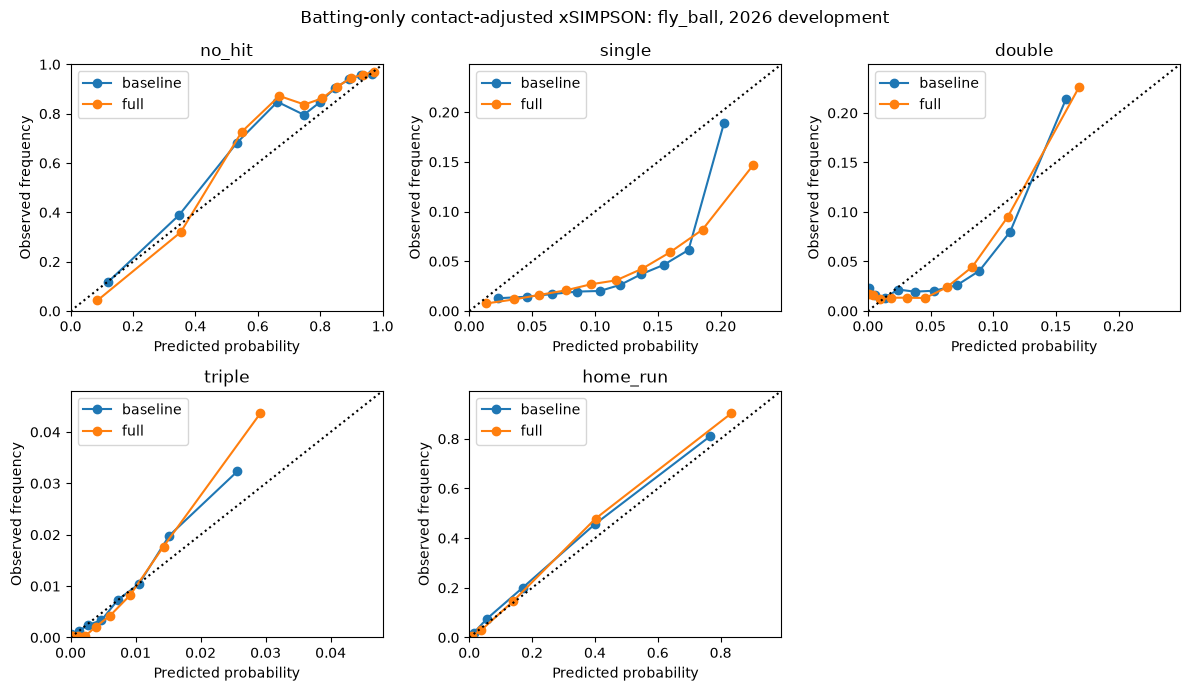

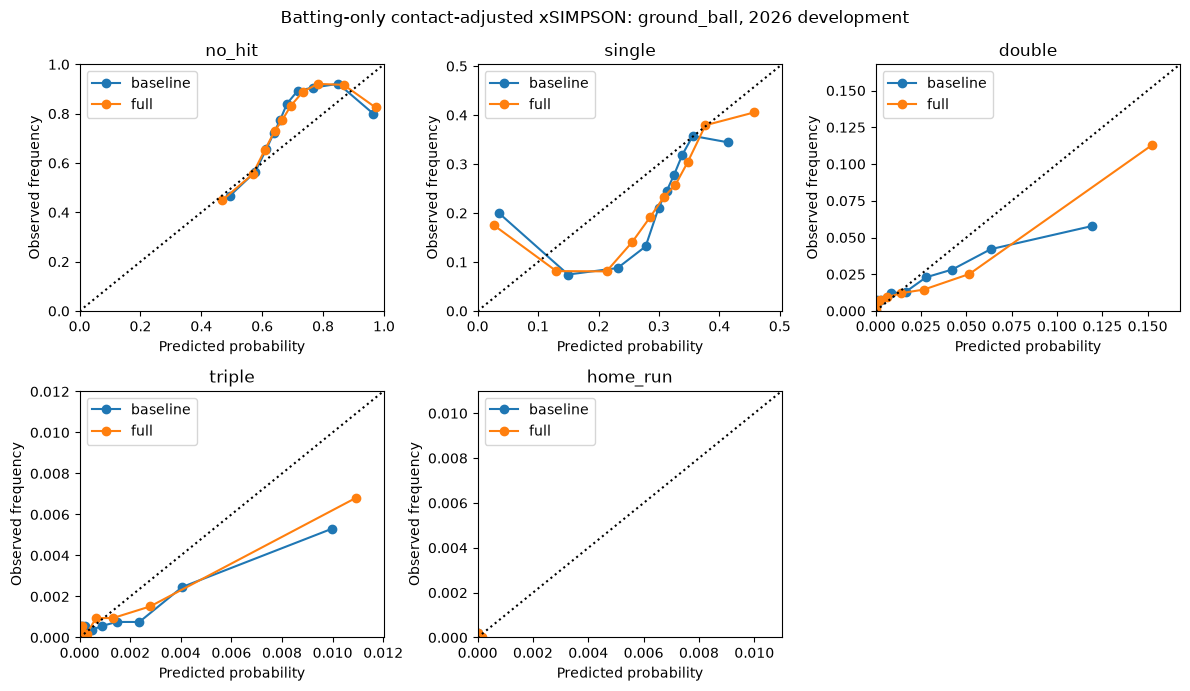

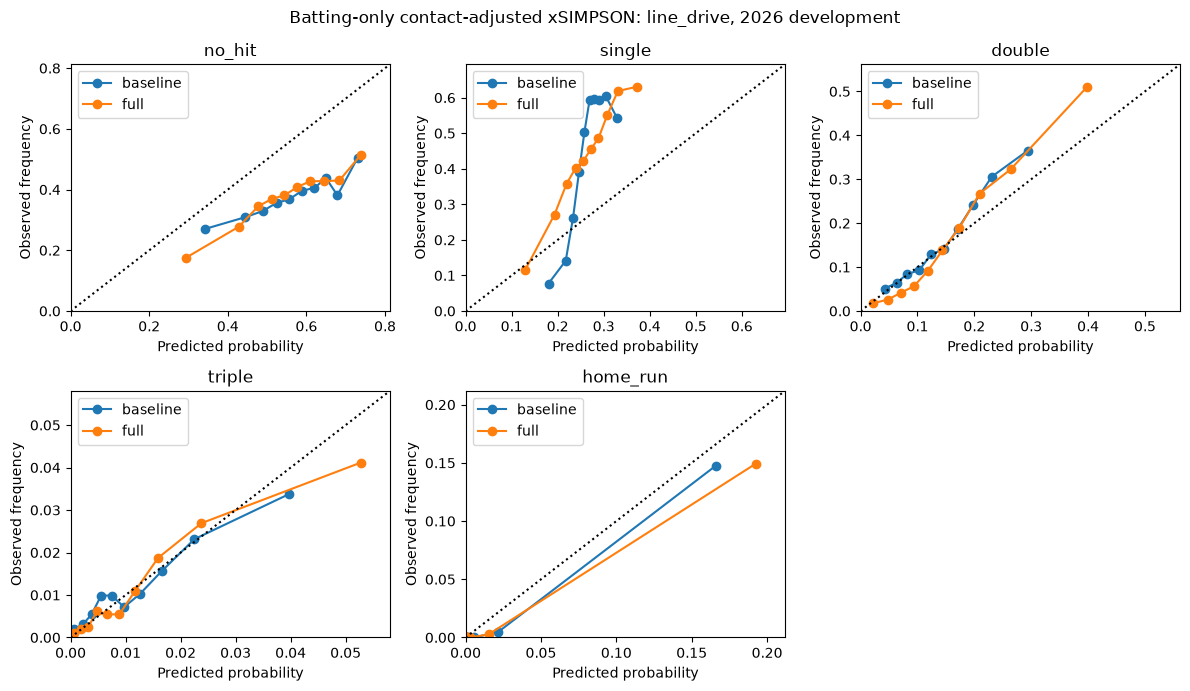

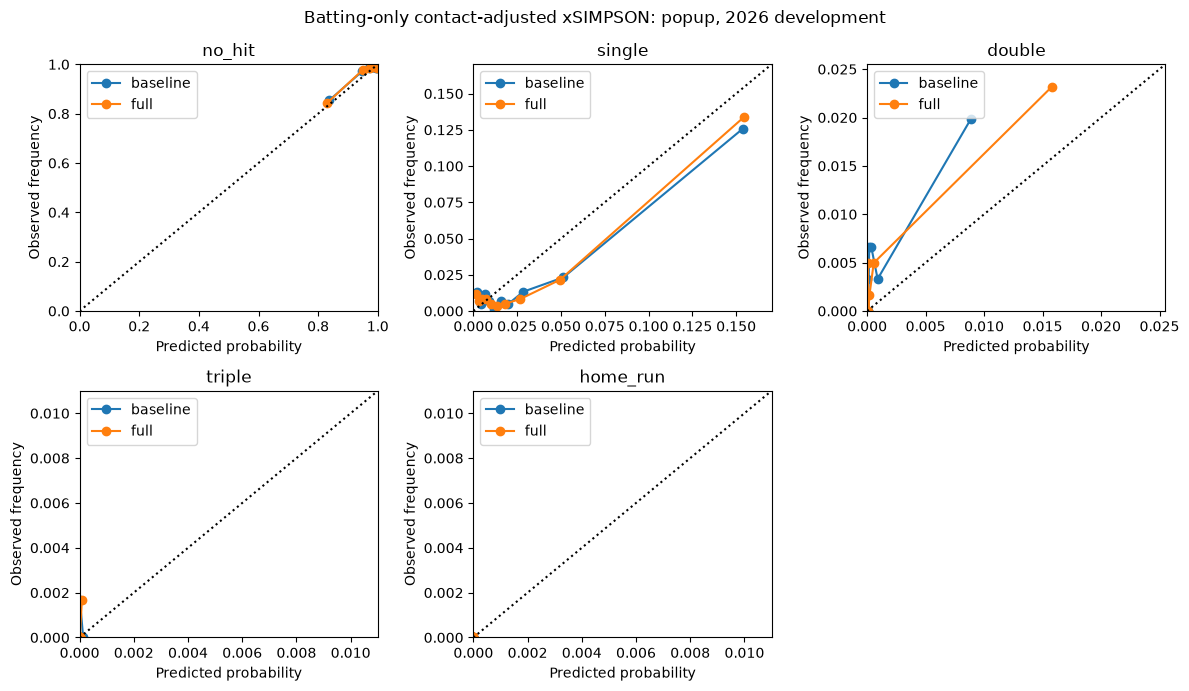

In [34]:
bat_calibration_rows = []
for group_name, group in [("overall", bat_eval)] + list(bat_eval.groupby("bb_group")):
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    for outcome, ax in zip(OUTCOMES, axes.flat):
        axis_limit = 0.01
        for name, probabilities in bat_probabilities.items():
            observed, predicted = calibration_curve(
                group["outcome"].eq(outcome).astype(int),
                probabilities.loc[group.index, outcome], n_bins=10, strategy="quantile",
            )
            ax.plot(predicted, observed, marker="o", label=name)
            axis_limit = max(axis_limit, predicted.max(), observed.max())
            for bin_id, (p, y) in enumerate(zip(predicted, observed), start=1):
                bat_calibration_rows.append({
                    "bb_type": group_name, "outcome": outcome, "model": name,
                    "bin": bin_id, "mean_prediction": p, "observed_rate": y,
                })
        limit = min(1.0, axis_limit * 1.1)
        ax.plot([0, limit], [0, limit], "k:")
        ax.set(xlim=(0, limit), ylim=(0, limit), title=outcome,
               xlabel="Predicted probability", ylabel="Observed frequency")
        ax.legend()
    axes.flat[-1].axis("off")
    fig.suptitle(f"Batting-only contact-adjusted xSIMPSON: {group_name}, 2026 development")
    fig.tight_layout()
    fig.savefig(LEADERBOARD_DIR / f"xsimpson_v3_batting_calibration_{group_name}.png", dpi=140)
    plt.show()
pd.DataFrame(bat_calibration_rows).to_csv(
    LEADERBOARD_DIR / "xsimpson_v3_batting_calibration.csv", index=False,
)

## Event-credit accounting

Read the evaluation season's actual Guts columns. Each event credit is its wOBA
weight divided by `wOBAScale`. These are positive event credits under the requested
convention, not runs above average or a complete offensive run-value estimate.

`xSIMPSON_bat = (walk_credit * uBB + HBP_credit * HBP + expected_contact_credit) / PA`,
where expected contact credit sums `P(single)*single_credit + P(double)*double_credit
+ P(triple)*triple_credit` over **every fair batted ball**.

HR remains one of the five mutually exclusive model outcomes, but its credit is
zero in this non-HR accounting. Actual HR plays remain in both model data and PA;
they can receive expected non-HR hit credit through their predicted alternatives.
Intentional walks receive zero credit while retaining PA. Strikeouts, caught
foul-outs, interference, and other non-contact PA also retain the denominator.
The observed counterpart uses actual non-HR hits and the same walks/HBP, credits,
and denominator. Values are reported **per PA**, without multiplying by 100.

In [35]:
weight_columns = ["wBB", "wHBP", "w1B", "w2B", "w3B", "wHR"]
guts = load_csv(DATA_DIR / "fangraphs-guts-data.csv", [
    "Season", "wOBAScale", *weight_columns,
])
for column in ["Season", "wOBAScale", *weight_columns]:
    guts[column] = pd.to_numeric(guts[column], errors="raise")
season_weights = guts.loc[guts["Season"].eq(TEST_YEAR)]
if len(season_weights) != 1:
    raise ValueError(f"Require exactly one Guts weight row for {TEST_YEAR}.")
bat_weights = season_weights.iloc[0]
if not np.isfinite(bat_weights[["wOBAScale", *weight_columns]]).all():
    raise ValueError("Required Guts weights or scale are missing/nonfinite.")
if bat_weights["wOBAScale"] <= 0 or bat_weights[weight_columns].lt(0).any():
    raise ValueError("Require a positive wOBA scale and nonnegative event weights.")
bat_run_credits = (bat_weights[weight_columns] / bat_weights["wOBAScale"]).rename({
    "wBB": "walk", "wHBP": "HBP", "w1B": "single", "w2B": "double",
    "w3B": "triple", "wHR": "home_run",
})
print("Evaluation-season wOBA scale:", bat_weights["wOBAScale"])
display(bat_run_credits.rename("weight_divided_by_scale").to_frame())
NON_HR_HITS = ["single", "double", "triple"]

Evaluation-season wOBA scale: 1.23784


,weight_divided_by_scale
walk,0.564066
HBP,0.589066
single,0.719065
double,1.019065
triple,1.289068
home_run,1.655626


In [36]:
for outcome in HIT_EVENTS:
    bat_eval[f"expected_{outcome}"] = bat_full_prob[outcome]
bat_eval["expected_contact_credit"] = bat_full_prob[NON_HR_HITS].dot(
    bat_run_credits[NON_HR_HITS]
)
bat_eval["baseline_expected_contact_credit"] = bat_baseline_prob[NON_HR_HITS].dot(
    bat_run_credits[NON_HR_HITS]
)
bat_contact_totals = bat_eval.groupby("batter").agg(
    expected_singles=("expected_single", "sum"),
    expected_doubles=("expected_double", "sum"),
    expected_triples=("expected_triple", "sum"),
    expected_home_runs=("expected_home_run", "sum"),
    expected_contact_credit=("expected_contact_credit", "sum"),
    baseline_expected_contact_credit=("baseline_expected_contact_credit", "sum"),
)
# A zero here means no fair-contact plays, not unscored/missing contact.
bat_players = bat_players.join(bat_contact_totals).fillna(0)
assert bat_eval.groupby("batter").size().sum() == bat_players["fair_batted_balls"].sum()
bat_players["walk_credit"] = bat_players["unintentional_walks"] * bat_run_credits["walk"]
bat_players["HBP_credit"] = bat_players["HBP"] * bat_run_credits["HBP"]
bat_players["walk_HBP_credit"] = bat_players["walk_credit"] + bat_players["HBP_credit"]
bat_players["observed_contact_credit"] = sum(
    bat_players[f"observed_{outcome}s"] * bat_run_credits[outcome]
    for outcome in NON_HR_HITS
)
bat_players["xSIMPSON_bat"] = (
    bat_players["walk_HBP_credit"] + bat_players["expected_contact_credit"]
) / bat_players["PA"]
bat_players["observed_SIMPSON_bat"] = (
    bat_players["walk_HBP_credit"] + bat_players["observed_contact_credit"]
) / bat_players["PA"]
bat_players["baseline_xSIMPSON_bat"] = (
    bat_players["walk_HBP_credit"] + bat_players["baseline_expected_contact_credit"]
) / bat_players["PA"]

### Additive batting-credit decomposition

Contact Value is non-HR expected contact credit at reference speed. Speed
Conversion Value is player-speed credit minus reference-speed credit, retaining
negative values. Walk/HBP Value is unchanged. Their sum equals the current
expected batting credit and `PA * xSIMPSON_bat`.

Reported runs per 600 PA are these positive event-credit units scaled by
`600 / PA`; they are not runs above average. Missing-speed and empirical-fallback
plays have zero individualized speed conversion. All PA, including HR and IBB,
remain in the denominator, while their own event credit is excluded.

In [37]:
bat_eval["reference_contact_credit"] = bat_reference_prob[NON_HR_HITS].dot(
    bat_run_credits[NON_HR_HITS]
)
bat_eval["speed_conversion_credit"] = (
    bat_eval["expected_contact_credit"] - bat_eval["reference_contact_credit"]
)
bat_eval["median_policy_contact_credit"] = bat_previous_median_prob[NON_HR_HITS].dot(
    bat_run_credits[NON_HR_HITS]
)
assert np.allclose(bat_eval.loc[missing_prior_speed, "speed_conversion_credit"], 0)
prior_fallback_rows = bat_eval["prediction_source"].eq("training_contact_fallback")
assert np.allclose(bat_eval.loc[prior_fallback_rows, "speed_conversion_credit"], 0)
components = bat_eval.groupby("batter").agg(
    contact_value=("reference_contact_credit", "sum"),
    speed_conversion_value=("speed_conversion_credit", "sum"),
    median_policy_contact_credit=("median_policy_contact_credit", "sum"),
    missing_prior_speed_contacts=("speed_missing", "sum"),
)
bat_players = bat_players.join(components).fillna(0)
bat_players["walk_HBP_value"] = bat_players["walk_HBP_credit"]
bat_players["expected_batting_credit"] = (
    bat_players["walk_HBP_value"] + bat_players["contact_value"]
    + bat_players["speed_conversion_value"]
)
assert np.allclose(bat_players["expected_batting_credit"], (
    bat_players["walk_HBP_credit"] + bat_players["expected_contact_credit"]
))
assert np.allclose(bat_players["expected_batting_credit"], bat_players["PA"] * bat_players["xSIMPSON_bat"])
for component, column in [
    ("walk_HBP_value", "walk_HBP_runs_per_600_PA"),
    ("contact_value", "contact_runs_per_600_PA"),
    ("speed_conversion_value", "speed_conversion_runs_per_600_PA"),
]:
    bat_players[column] = 600 * bat_players[component] / bat_players["PA"]
bat_players["batting_credit_per_600_PA"] = 600 * bat_players["xSIMPSON_bat"]
bat_players["reference_speed"] = reference_speed

In [38]:
bat_routes = pd.crosstab(bat_eval["batter"], bat_eval["prediction_source"]).reindex(
    index=bat_players.index,
    columns=["full_model", "baseline_direction_fallback", "training_contact_fallback"],
).fillna(0).astype(int)
assert bat_routes.sum(axis=1).eq(bat_players["fair_batted_balls"]).all()
contact_denominator = bat_players["fair_batted_balls"].where(
    bat_players["fair_batted_balls"].gt(0)
)
for route in bat_routes.columns:
    bat_players[f"{route}_contacts"] = bat_routes[route]
    bat_players[f"{route}_fraction"] = bat_routes[route] / contact_denominator
bat_players["contact_measurement_coverage"] = (
    bat_routes["full_model"] + bat_routes["baseline_direction_fallback"]
) / contact_denominator
bat_players["prediction_coverage"] = bat_routes.sum(axis=1) / contact_denominator
bat_eval["speed_replacement_used"] = (
    bat_eval["speed_missing"].eq(1) & bat_eval["baseline_available"]
)
bat_players["speed_replacement_fraction"] = (
    bat_eval.groupby("batter")["speed_replacement_used"].sum()
    .reindex(bat_players.index, fill_value=0) / contact_denominator
)
assert bat_players.loc[contact_denominator.notna(), "prediction_coverage"].eq(1).all()
assert np.isfinite(bat_players[["xSIMPSON_bat", "observed_SIMPSON_bat"]]).all().all()

In [39]:
bat_players["missing_prior_speed_fraction"] = (
    bat_players["missing_prior_speed_contacts"] / contact_denominator
)
bat_players["xSIMPSON_bat_previous_median"] = (
    bat_players["walk_HBP_credit"] + bat_players["median_policy_contact_credit"]
) / bat_players["PA"]
bat_players["missing_speed_policy_rate_change"] = (
    bat_players["xSIMPSON_bat"] - bat_players["xSIMPSON_bat_previous_median"]
)
if season_validation is not None:
    bat_players = bat_players.join(season_validation[["official_PA", "PA_difference"]])
    bat_players["official_PA_rate_sensitivity"] = (
        bat_players["expected_batting_credit"] / bat_players["official_PA"]
    )
sensitivity_rows = []
for label, probabilities, speed in [
    ("previous_training_median", bat_previous_median_prob, bat_median_speed),
    ("reference_speed_missing", bat_full_prob, reference_speed),
]:
    contact_credit = probabilities[NON_HR_HITS].dot(bat_run_credits[NON_HR_HITS]).sum()
    total_credit = bat_players["walk_HBP_credit"].sum() + contact_credit
    sensitivity_rows.append({
        "policy": label, "missing_speed_input": speed,
        "expected_batting_credit": total_credit,
        "aggregate_xSIMPSON_bat": total_credit / bat_players["PA"].sum(),
        "multiclass_log_loss": log_loss(
            bat_eval["outcome_code"], probabilities, labels=np.arange(len(OUTCOMES)),
        ),
    })
bat_sensitivity = pd.DataFrame(sensitivity_rows)
display(bat_sensitivity.round(8))
bat_sensitivity.to_csv(LEADERBOARD_DIR / "xsimpson_v3_missing_speed_sensitivity.csv", index=False)
print("Players with negative speed conversion:", bat_players["speed_conversion_value"].lt(0).sum())
print("Missing-speed policy affects only inference; no 2026 tuning or refitting.")

,policy,missing_speed_input,expected_batting_credit,aggregate_xSIMPSON_bat,multiclass_log_loss
0,previous_training_median,27.500000,37363.109075,0.203227,0.692361
1,reference_speed_missing,27.384378,37410.675680,0.203486,0.692383


Players with negative speed conversion: 220
Missing-speed policy affects only inference; no 2026 tuning or refitting.


In [40]:
bat_players = bat_players.join(
    player_names.set_index("batter")[["Name"]], validate="one_to_one",
)
bat_players = bat_players[["Name"] + [c for c in bat_players if c != "Name"]]
bat_players = bat_players.sort_values("xSIMPSON_bat", ascending=False)
BATTING_DISPLAY_MIN_PA = 502  # Same display threshold as v2; CSV retains all players.
print("Batting-only, contact-adjusted xSIMPSON per PA; display PA >=", BATTING_DISPLAY_MIN_PA)
bat_display_columns = [
    "Name", "PA", "fair_batted_balls", "expected_singles", "expected_doubles",
    "expected_triples", "walk_HBP_credit", "expected_contact_credit",
    "xSIMPSON_bat", "observed_SIMPSON_bat", "contact_measurement_coverage",
    "walk_HBP_runs_per_600_PA", "contact_runs_per_600_PA",
    "speed_conversion_runs_per_600_PA", "missing_prior_speed_fraction",
    "baseline_direction_fallback_fraction", "training_contact_fallback_fraction",
]
display(bat_players.loc[
    bat_players["PA"].ge(BATTING_DISPLAY_MIN_PA), bat_display_columns
].head(20).round(4))
print("Chandler Simpson: excluded from both model fitting and all fallback estimates.")
display(bat_players.loc[bat_players.index == SIMPSON_ID, bat_display_columns].round(4))
bat_players.to_csv(LEADERBOARD_DIR / "xsimpson_v3_batting_results.csv")
print("Saved batting-only results for", len(bat_players), "players.")
# Qualified display leaderboard; the results/decomposition CSV retains every PA player.
bat_players.loc[
    bat_players["PA"].ge(BATTING_DISPLAY_MIN_PA), bat_display_columns
].to_csv(LEADERBOARD_DIR / "xsimpson_v3_batting_leaderboard.csv")
bat_players.to_csv(LEADERBOARD_DIR / "xsimpson_v3_batting_decomposition.csv")


Batting-only, contact-adjusted xSIMPSON per PA; display PA >= 502


,Name,PA,fair_batted_balls,expected_singles,expected_doubles,expected_triples,walk_HBP_credit,expected_contact_credit,xSIMPSON_bat,observed_SIMPSON_bat,contact_measurement_coverage,walk_HBP_runs_per_600_PA,contact_runs_per_600_PA,speed_conversion_runs_per_600_PA,missing_prior_speed_fraction,baseline_direction_fallback_fraction,training_contact_fallback_fraction
batter,,,,,,,,,,,,,,,,,
803011,Sam Antonacci,557,398,94.2989,25.6918,3.9057,41.3377,99.0234,0.2520,0.2531,0.9950,44.5290,106.6679,0.0000,1.0,0.0000,0.0050
680757,Steven Kwan,637,476,115.7771,24.5679,1.6964,49.7378,110.4744,0.2515,0.2589,0.9979,46.8488,104.2569,-0.1993,0.0,0.0000,0.0021
672695,Geraldo Perdomo,680,488,112.2128,27.4142,2.3456,57.0956,111.6489,0.2482,0.2463,0.9959,50.3785,98.9540,-0.4403,0.0,0.0000,0.0041
800050,Chase DeLauter,559,404,90.0927,28.9496,4.0864,33.8689,99.5517,0.2387,0.2418,0.9950,36.3531,106.8534,0.0000,1.0,0.0000,0.0050
672515,Gabriel Moreno,549,394,91.5305,24.3996,1.3567,37.3533,92.4301,0.2364,0.2587,0.9975,40.8233,101.9043,-0.8878,0.0,0.0000,0.0025
693304,Nick Gonzales,608,451,113.2207,25.2804,3.1399,31.9127,111.2231,0.2354,0.2572,0.9956,31.4928,105.0309,4.7286,0.0,0.0000,0.0044
681198,TJ Rumfield,631,452,93.9098,27.1963,4.9916,46.5034,101.6766,0.2348,0.2593,0.9934,44.2187,96.6814,0.0000,1.0,0.0022,0.0066
663538,Nico Hoerner,689,569,137.2693,28.3377,2.9618,30.1455,131.4016,0.2345,0.2211,0.9930,26.2515,110.7555,3.6726,0.0,0.0000,0.0070
808982,Jung Hoo Lee,579,477,110.5924,29.9038,4.2747,19.9173,115.5074,0.2339,0.2270,0.9979,20.6397,117.0920,2.6048,0.0,0.0000,0.0021


Chandler Simpson: excluded from both model fitting and all fallback estimates.


,Name,PA,fair_batted_balls,expected_singles,expected_doubles,expected_triples,walk_HBP_credit,expected_contact_credit,xSIMPSON_bat,observed_SIMPSON_bat,contact_measurement_coverage,walk_HBP_runs_per_600_PA,contact_runs_per_600_PA,speed_conversion_runs_per_600_PA,missing_prior_speed_fraction,baseline_direction_fallback_fraction,training_contact_fallback_fraction
batter,,,,,,,,,,,,,,,,,
802415,Chandler Simpson,612,530,136.0246,20.0044,2.9939,14.1016,122.0558,0.2225,0.2421,0.9943,13.8251,110.21,9.4525,0.0,0.0,0.0057


Saved batting-only results for 662 players.


## Comparison with v2 and remaining limits

The inspected `SIMPSONv2/main.ipynb` computes observed non-HR hit credit as
`(1B*w1B + 2B*w2B + 3B*w3B) / wOBAScale`, adds observed `BsR`, and reports
`100 * (hit_credit + BsR) / PA`. It omits walk and HBP credit. Its plus column
also depends on the selected baseline sample. This v3 score instead adds uBB/HBP
credit, replaces observed hits with contact-adjusted probabilities, omits BsR,
and reports per PA. Multiplying v3 by 100 changes its display scale but does not
make its accounting equivalent to v2. Neither the new rate nor its observed
counterpart is xSIMPSON+ or runs above average.

The saved table retains every evaluation player with PA, including players with
no fair contact. Coverage fractions are undefined for those with zero contact.
Expected HR counts are diagnostic only; no HR or intentional-walk credit enters
the score. Every fair contact has a prediction, including explicit fallbacks.

2026 remains a development evaluation. Improved prediction does not establish
repeatable player placement skill, and this contact-adjusted accounting is not a
prospective forecast. Fair/foul classification uses play text; direction is a
chart-coordinate approximation. Missing-contact fallback rates may not represent
a given player, and defensive positioning, parks, and other context remain
unmodeled. Baserunning and an untouched prospective evaluation remain later stages.

## Statcast xwOBA benchmark on shared scored plays

This benchmark includes HR and uses **raw wOBA units**, with no division by
`wOBAScale`. The cached `estimated_woba_using_speedangle` is used directly as a
scalar; no Statcast class probabilities are inferred. [Statcast field definitions](https://baseballsavant.mlb.com/csv-docs)
also identify the observed `woba_value` and denominator fields.

The supplied Statcast hit weights differ from this project's Guts weights.
For an aligned benchmark only, convert our probabilities with the unique observed
2026 Statcast hit weights (including HR), and compare both predictions with
Statcast's observed event weights. Retain full-model direct-scored fair contact
with available xwOBA and denominator 1. Exclude plays whose supplied observed
weight conflicts with the five-class convention, such as credited errors/choices;
report those exclusions explicitly. Local Guts weights remain unchanged for
batting accounting. A scalar xwOBA cannot be exactly reweighted to different
Guts weights without its underlying class probabilities.

Mean prediction error is predicted minus observed wOBA on identical shared plays;
it measures average bias. This is a batted-ball subset benchmark, not full-season
wOBA, a prospective validation, or proof that either model estimates causal skill.

In [41]:
benchmark_source = None
benchmark_path = DATA_DIR / f"statcast_expected_woba_{TEST_YEAR}.csv"
if benchmark_path.is_file():
    benchmark_source = load_csv(benchmark_path, [
        *pitch_keys, "batter", "events", "game_type",
        "estimated_woba_using_speedangle", "woba_value", "woba_denom",
    ])
    assert not benchmark_source.duplicated(pitch_keys).any()
    statcast_hit_weights = benchmark_source.loc[
        benchmark_source["game_type"].eq("R") & benchmark_source["events"].isin(HIT_EVENTS)
    ].groupby("events")["woba_value"].agg(["min", "max", "nunique"])
    assert set(statcast_hit_weights.index) == set(HIT_EVENTS)
    assert statcast_hit_weights["nunique"].eq(1).all()
    benchmark_weights = statcast_hit_weights["min"].reindex(OUTCOMES).fillna(0)
    benchmark_weight_audit = pd.DataFrame({
        "Statcast_raw_wOBA_weight": benchmark_weights,
        "Guts_raw_wOBA_weight": pd.Series({
            "no_hit": 0, "single": bat_weights["w1B"], "double": bat_weights["w2B"],
            "triple": bat_weights["w3B"], "home_run": bat_weights["wHR"],
        }),
    })
    display(benchmark_weight_audit)
    benchmark_weight_audit.to_csv(LEADERBOARD_DIR / "xsimpson_v3_benchmark_weights.csv")
else:
    print("Statcast xwOBA benchmark unavailable:", benchmark_path)

,Statcast_raw_wOBA_weight,Guts_raw_wOBA_weight
no_hit,0.00,0.000000
single,0.90,0.890088
double,1.25,1.261440
triple,1.60,1.595660
home_run,2.00,2.049400


In [42]:
if benchmark_source is not None:
    benchmark_data = bat_eval[[*pitch_keys, "batter", "outcome", "bb_group"]].merge(
        benchmark_source.drop(columns=["events", "game_type"]),
        on=[*pitch_keys, "batter"], how="left", validate="one_to_one",
    )
    benchmark_data.index = bat_eval.index
    benchmark_data["class_observed_weight"] = benchmark_data["outcome"].map(benchmark_weights)
    benchmark_data["full_scored"] = bat_full_rows
    benchmark_data["xwOBA_available"] = np.isfinite(
        benchmark_data["estimated_woba_using_speedangle"]
    )
    benchmark_data["accounting_matches"] = np.isclose(
        benchmark_data["woba_value"], benchmark_data["class_observed_weight"]
    )
    benchmark_data["shared"] = (
        benchmark_data["full_scored"] & benchmark_data["xwOBA_available"]
        & benchmark_data["woba_denom"].eq(1) & benchmark_data["accounting_matches"]
    )
    benchmark_data["baseline_wOBA"] = bat_baseline_prob.dot(benchmark_weights)
    benchmark_data["full_wOBA"] = bat_full_prob.dot(benchmark_weights)
    print("Fair contact:", len(benchmark_data), "direct full-model rows:", bat_full_rows.sum())
    print("Available Statcast xwOBA:", benchmark_data["xwOBA_available"].sum())
    print("Observed-accounting conflicts among direct scored rows:", (
        benchmark_data["full_scored"] & ~benchmark_data["accounting_matches"]
    ).sum())
    print("Shared benchmark rows:", benchmark_data["shared"].sum())

Fair contact: 120973 direct full-model rows: 120404
Available Statcast xwOBA: 119752
Observed-accounting conflicts among direct scored rows: 2103
Shared benchmark rows: 118259


In [43]:
if benchmark_source is not None:
    benchmark_rows = []
    for bb_type, group in [("overall", benchmark_data)] + list(benchmark_data.groupby("bb_group")):
        shared = group.loc[group["shared"]]
        if shared.empty:
            continue
        for name, prediction_column in [
            ("baseline", "baseline_wOBA"), ("full", "full_wOBA"),
            ("Statcast_xwOBA", "estimated_woba_using_speedangle"),
        ]:
            error = shared[prediction_column] - shared["woba_value"]
            benchmark_rows.append({
                "bb_type": bb_type, "model": name, "shared_rows": len(shared),
                "fair_contact_rows": len(group), "direct_scored_rows": group["full_scored"].sum(),
                "coverage_of_direct_scored": len(shared) / group["full_scored"].sum(),
                "observed_mean_wOBA": shared["woba_value"].mean(),
                "predicted_mean_wOBA": shared[prediction_column].mean(),
                "mean_prediction_error": error.mean(), "RMSE": np.sqrt(np.mean(error ** 2)),
            })
    benchmark_results = pd.DataFrame(benchmark_rows)
    display(benchmark_results.round(6))
    benchmark_results.to_csv(LEADERBOARD_DIR / "xsimpson_v3_statcast_xwoba_benchmark.csv", index=False)

,bb_type,model,shared_rows,fair_contact_rows,direct_scored_rows,coverage_of_direct_scored,observed_mean_wOBA,predicted_mean_wOBA,mean_prediction_error,RMSE
0,overall,baseline,118259,120973,120404,0.982185,0.379517,0.367991,-0.011526,0.472288
1,overall,full,118259,120973,120404,0.982185,0.379517,0.369093,-0.010424,0.447782
2,overall,Statcast_xwOBA,118259,120973,120404,0.982185,0.379517,0.373807,-0.005710,0.432637
3,fly_ball,baseline,32637,32765,32703,0.997982,0.422862,0.461395,0.038533,0.542597
4,fly_ball,full,32637,32765,32703,0.997982,0.422862,0.459801,0.036938,0.484531
5,fly_ball,Statcast_xwOBA,32637,32765,32703,0.997982,0.422862,0.415211,-0.007651,0.514615
6,ground_ball,baseline,50303,52796,52310,0.961633,0.238741,0.285608,0.046867,0.397207
7,ground_ball,full,50303,52796,52310,0.961633,0.238741,0.280218,0.041476,0.392744
8,ground_ball,Statcast_xwOBA,50303,52796,52310,0.961633,0.238741,0.231095,-0.007646,0.375251
9,line_drive,baseline,29312,29375,29358,0.998433,0.645643,0.474927,-0.170716,0.544821


The final headline uses the reference-speed missing-data policy consistently in
probabilities, credit, decomposition, and model evaluation. Training retains the
previous median imputation and all existing model settings. Negative speed
conversion is preserved. Four zero-contact players, if present, retain PA and
walk/HBP accounting, with undefined contact fractions.

Independent season totals can reveal player-attribution differences even when
league totals agree. Those discrepancies remain flagged, with an alternate
PA-denominator sensitivity, rather than silently moving event records. Statcast's
observed-event accounting and weight differences limit the benchmark to an
explicitly matched subset. All results remain a 2026 development evaluation;
model-based speed association is not a causal or prospective speed forecast.
Baserunning remains separate.

Missing-speed training rows were fitted at the old median with a missingness
indicator. Moving those rows to reference speed at inference can change predictions
through fitted interactions, even though individualized speed conversion is zero.
Treat the resulting headline sensitivity as an imputation-policy effect, not as
measured speed skill. The old-median headline is retained for comparison.

Inspect benchmark errors within batted-ball type as well as overall: offsetting
conditional biases can cancel in the aggregate. This diagnostic does not justify
retuning on the 2026 development sample.
